# Experiment 5: Reinforcement learning (tabular Q-learning)
Aniruddh Vijayvargia (500125613), Batch D. Lab Manual, Chapter 6.

A 5 x 7 grid world with walls, a goal (+10), a pit (-10) and a step cost of -0.1.
Q-learning is run for four exploration rates; the greedy policy is extracted and
checked against the shortest safe route found by breadth-first search.

In [1]:
import json, os, platform
from collections import deque
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})
R = {"versions": {"python": platform.python_version(), "numpy": np.__version__,
                  "matplotlib": matplotlib.__version__}}

In [2]:
H, W = 5, 7
WALLS = {(1, 2), (2, 2), (3, 2), (1, 4), (2, 4)}
GOAL, PIT, START = (0, W - 1), (2, W - 1), (H - 1, 0)
A = [(-1, 0), (1, 0), (0, -1), (0, 1)]            # up, down, left, right
ARROW = ["↑", "↓", "←", "→"]
STEP_COST, GOAL_R, PIT_R = -0.1, 10.0, -10.0

def step(s, a):
    r, c = s; dr, dc = A[a]; nr, nc = r + dr, c + dc
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c                               # bumping a wall wastes the step
    ns = (nr, nc)
    if ns == GOAL: return ns, GOAL_R, True
    if ns == PIT:  return ns, PIT_R, True
    return ns, STEP_COST, False

In [3]:
ALPHA, GAMMA, EPISODES, STEP_CAP, SEED = 0.5, 0.95, 600, 120, 613

def train(eps, episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=SEED):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    curve = []
    for _ in range(episodes):
        s, total = START, 0.0
        for _ in range(STEP_CAP):
            a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s[0], s[1]]))
            ns, r, done = step(s, a)
            total += r
            target = r + gamma * np.max(Q[ns[0], ns[1]]) * (not done)   # no future after a terminal state
            Q[s[0], s[1], a] += alpha * (target - Q[s[0], s[1], a])     # TD update
            s = ns
            if done:
                break
        curve.append(total)
    return Q, np.array(curve)

def smooth(v, k=25):
    return np.convolve(v, np.ones(k) / k, mode="valid")

def greedy_rollout(Q, max_steps=50):
    s, path, ret = START, [START], 0.0
    for _ in range(max_steps):
        ns, r, done = step(s, int(np.argmax(Q[s[0], s[1]])))
        ret += r; path.append(ns); s = ns
        if done:
            return path, ret, ns == GOAL
    return path, ret, False

def shortest_to_goal():
    """BFS length from START to GOAL avoiding walls and the pit: the optimal step count."""
    dist, q = {START: 0}, deque([START])
    while q:
        s = q.popleft()
        for dr, dc in A:
            n = (s[0] + dr, s[1] + dc)
            if 0 <= n[0] < H and 0 <= n[1] < W and n not in WALLS and n != PIT and n not in dist:
                dist[n] = dist[s] + 1; q.append(n)
    return dist[GOAL]

OPT_STEPS = shortest_to_goal()
OPT_RETURN = (OPT_STEPS - 1) * STEP_COST + GOAL_R
print("optimal:", OPT_STEPS, "steps, return", OPT_RETURN)

optimal: 10 steps, return 9.1


In [4]:
EPS_LIST = (0.01, 0.10, 0.20, 0.50)
results, curves, Qs = [], {}, {}
for eps in EPS_LIST:
    Q, curve = train(eps)
    Qs[eps], curves[eps] = Q, curve
    path, ret, reached = greedy_rollout(Q)
    first_goal = int(np.argmax(curve > 0)) if (curve > 0).any() else None
    results.append({"eps": eps, "mean_last100": float(curve[-100:].mean()),
                    "std_last100": float(curve[-100:].std()), "first_goal_episode": first_goal,
                    "greedy_steps": len(path) - 1, "greedy_return": ret, "greedy_reaches_goal": reached,
                    "greedy_optimal": reached and len(path) - 1 == OPT_STEPS})
    print(results[-1])
R["params"] = {"grid": [H, W], "walls": sorted(WALLS), "goal": GOAL, "pit": PIT, "start": START,
               "rewards": {"goal": GOAL_R, "pit": PIT_R, "step": STEP_COST}, "alpha": ALPHA,
               "gamma": GAMMA, "episodes": EPISODES, "step_cap": STEP_CAP, "seed": SEED,
               "optimal_steps": OPT_STEPS, "optimal_return": OPT_RETURN}
R["eps"] = results

{'eps': 0.01, 'mean_last100': 9.093, 'std_last100': 0.043023249528597915, 'first_goal_episode': 3, 'greedy_steps': 10, 'greedy_return': 9.1, 'greedy_reaches_goal': True, 'greedy_optimal': True}
{'eps': 0.1, 'mean_last100': 8.415999999999999, 'std_last100': 3.3698284822821467, 'first_goal_episode': 3, 'greedy_steps': 10, 'greedy_return': 9.1, 'greedy_reaches_goal': True, 'greedy_optimal': True}


{'eps': 0.2, 'mean_last100': 7.29, 'std_last100': 5.345923680712248, 'first_goal_episode': 2, 'greedy_steps': 10, 'greedy_return': 9.1, 'greedy_reaches_goal': True, 'greedy_optimal': True}
{'eps': 0.5, 'mean_last100': 7.8420000000000005, 'std_last100': 2.1252849220751555, 'first_goal_episode': 4, 'greedy_steps': 10, 'greedy_return': 9.1, 'greedy_reaches_goal': True, 'greedy_optimal': True}


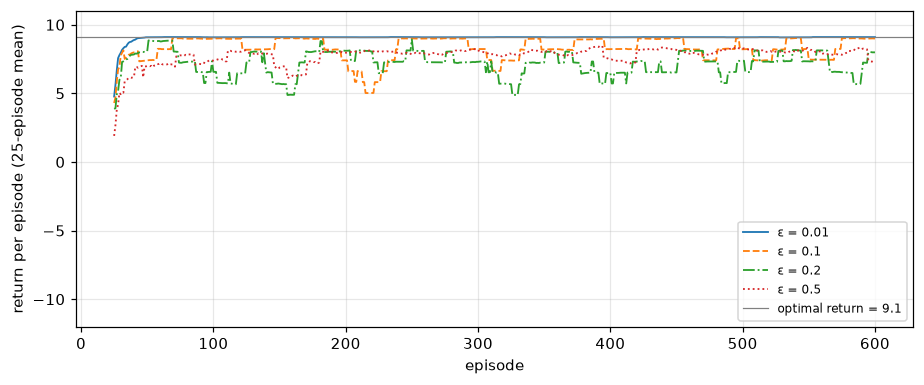

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for eps, ls in zip(EPS_LIST, ["-", "--", "-.", ":"]):
    ax.plot(np.arange(25, EPISODES + 1), smooth(curves[eps]), ls, lw=1.2, label=f"ε = {eps}")
ax.axhline(OPT_RETURN, color="0.5", lw=0.8, label=f"optimal return = {OPT_RETURN:.1f}")
ax.set_xlabel("episode"); ax.set_ylabel("return per episode (25-episode mean)")
ax.set_ylim(-12, 11); ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig5_1_learning_curves.png")

→ → → → → → G
← ↑ # ↑ # ↑ ↑
→ ↑ # ↑ # ↑ P
→ ↓ # → → ↑ ←
→ → → → → ↑ ↑


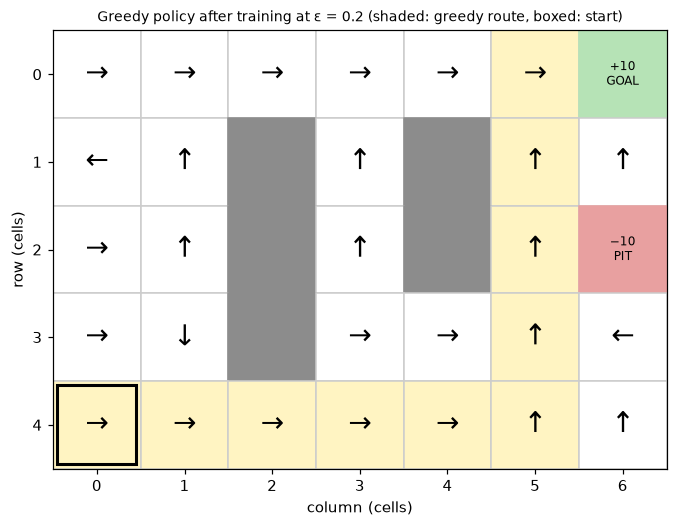

In [6]:
POLICY_EPS = 0.20
Q = Qs[POLICY_EPS]
policy = np.argmax(Q, axis=2)
path, _, _ = greedy_rollout(Q)
grid_txt = []
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for r in range(H):
    row = []
    for c in range(W):
        cell = (r, c)
        if cell in WALLS:
            ax.add_patch(plt.Rectangle((c, r), 1, 1, color="0.55")); row.append("#")
        elif cell == GOAL:
            ax.add_patch(plt.Rectangle((c, r), 1, 1, color="#b6e3b6"))
            ax.text(c + .5, r + .5, "+10\nGOAL", ha="center", va="center", fontsize=8); row.append("G")
        elif cell == PIT:
            ax.add_patch(plt.Rectangle((c, r), 1, 1, color="#e8a0a0"))
            ax.text(c + .5, r + .5, "−10\nPIT", ha="center", va="center", fontsize=8); row.append("P")
        else:
            face = "#fff4c2" if cell in path else "w"
            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=face, edgecolor="0.8"))
            ax.text(c + .5, r + .5, ARROW[policy[r, c]], ha="center", va="center", fontsize=18)
            row.append(ARROW[policy[r, c]])
    grid_txt.append(" ".join(row))
ax.add_patch(plt.Rectangle((START[1] + .05, START[0] + .05), .9, .9, fill=False, lw=2, ec="k"))
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect("equal")
ax.set_xticks(np.arange(W) + .5, range(W)); ax.set_yticks(np.arange(H) + .5, range(H))
ax.set_xlabel("column (cells)"); ax.set_ylabel("row (cells)")
ax.set_title(f"Greedy policy after training at ε = {POLICY_EPS} (shaded: greedy route, boxed: start)", fontsize=9)
fig.tight_layout(); fig.savefig("figs/fig5_2_policy.png")
R["policy_grid"] = grid_txt
R["policy_eps"] = POLICY_EPS
print("\n".join(grid_txt))

In [7]:
with open("results.json", "w") as fh:
    json.dump(R, fh, indent=2)
print("saved results.json")

saved results.json
